In [7]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
import torch.nn as nn
import torch.optim as optim

In [8]:
data = pd.read_csv("train.csv")

data['date'] = pd.to_datetime(data['date'])

store_id = 1
item_id = 1

df = data[
    (data['store'] == store_id) &
    (data['item'] == item_id)
].copy()

df = df.sort_values('date')

In [9]:
df['lag_1'] = df['sales'].shift(1)
df['lag_7'] = df['sales'].shift(7)
df['lag_30'] = df['sales'].shift(30)

df['rolling_7'] = (
    df['sales']
    .shift(1)
    .rolling(7)
    .mean()
)

df['rolling_30'] = (
    df['sales']
    .shift(1)
    .rolling(30)
    .mean()
)

df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek

df = df.dropna()

In [10]:
features = [
    'lag_1',
    'lag_7',
    'lag_30',
    'rolling_7',
    'rolling_30',
    'month',
    'day_of_week'
]

X = df[features]
y = df['sales']

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_valid = X.iloc[split:]

y_train = y.iloc[:split]
y_valid = y.iloc[split:]

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

In [12]:
X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_valid_tensor = torch.tensor(
    X_valid_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.float32
).view(-1,1)

y_valid_tensor = torch.tensor(
    y_valid.values,
    dtype=torch.float32
).view(-1,1)

In [13]:
print("X_train_tensor shape:", X_train_tensor.shape)
print("X_valid_tensor shape:", X_valid_tensor.shape)

print("y_train_tensor shape:", y_train_tensor.shape)
print("y_valid_tensor shape:", y_valid_tensor.shape)

X_train_tensor shape: torch.Size([1436, 7])
X_valid_tensor shape: torch.Size([360, 7])
y_train_tensor shape: torch.Size([1436, 1])
y_valid_tensor shape: torch.Size([360, 1])


In [14]:
class DemandANN(nn.Module):

    def __init__(self):

        super(DemandANN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(7, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)

        )

    def forward(self, x):

        return self.network(x)

In [15]:
model = DemandANN()

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [41]:
epochs = 200

train_losses = []

for epoch in range(epochs):

    model.train()

    predictions = model(X_train_tensor)

    loss = criterion(
        predictions,
        y_train_tensor
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {loss.item():.4f}"
        )

Epoch [10/200] Loss: 15.9544
Epoch [20/200] Loss: 15.9344
Epoch [30/200] Loss: 15.9148
Epoch [40/200] Loss: 15.8938
Epoch [50/200] Loss: 15.8730
Epoch [60/200] Loss: 15.8519
Epoch [70/200] Loss: 15.8310
Epoch [80/200] Loss: 15.8092
Epoch [90/200] Loss: 15.7880
Epoch [100/200] Loss: 15.7671
Epoch [110/200] Loss: 15.7457
Epoch [120/200] Loss: 15.7249
Epoch [130/200] Loss: 15.7052
Epoch [140/200] Loss: 15.6846
Epoch [150/200] Loss: 15.6634
Epoch [160/200] Loss: 15.6428
Epoch [170/200] Loss: 15.6206
Epoch [180/200] Loss: 15.5961
Epoch [190/200] Loss: 15.5709
Epoch [200/200] Loss: 15.5391


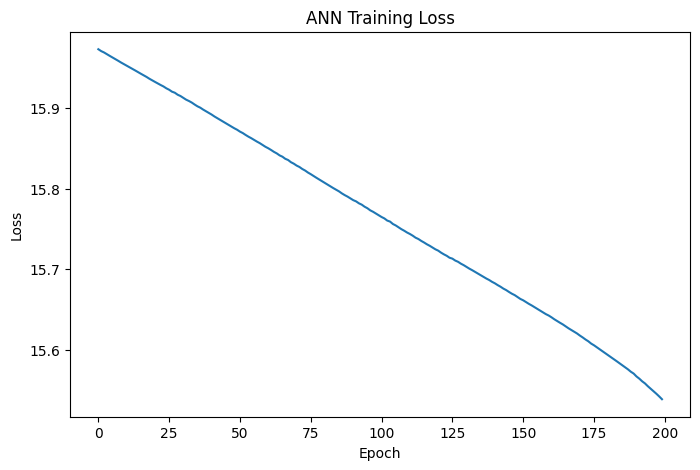

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(train_losses)

plt.title("ANN Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.show()

In [43]:
model.eval()

with torch.no_grad():

    ann_predictions = model(
        X_valid_tensor
    ).numpy().flatten()

In [44]:
ann_mae = mean_absolute_error(
    y_valid,
    ann_predictions
)

ann_rmse = np.sqrt(
    mean_squared_error(
        y_valid,
        ann_predictions
    )
)

print("ANN MAE:", ann_mae)

print("ANN RMSE:", ann_rmse)

ANN MAE: 4.311069965362549
ANN RMSE: 5.322018163685157


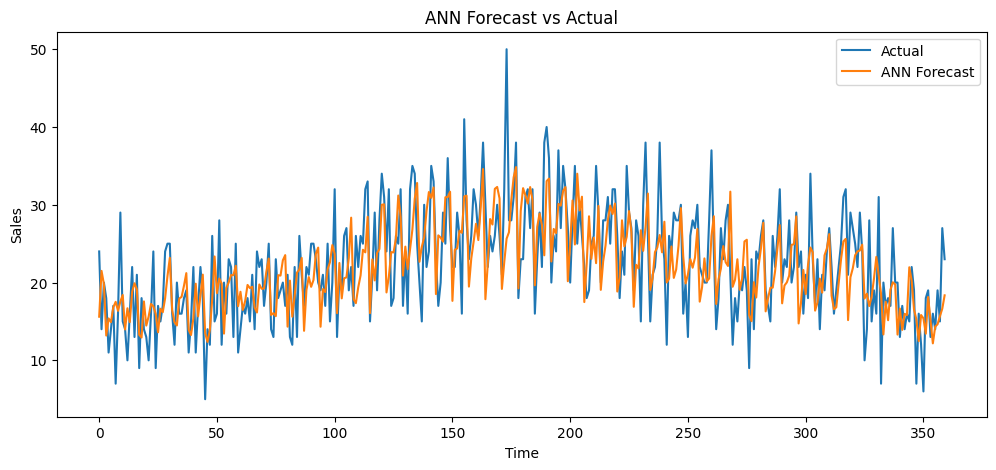

In [45]:
plt.figure(figsize=(12,5))

plt.plot(
    y_valid.values,
    label="Actual"
)

plt.plot(
    ann_predictions,
    label="ANN Forecast"
)

plt.title("ANN Forecast vs Actual")

plt.xlabel("Time")

plt.ylabel("Sales")

plt.legend()

plt.show()